# 17 — El clima completo: sol, nubes, rachas y cambios bruscos

## Pregunta y alcance

El clima que se había usado hasta aquí era una temperatura y un indicador de si llovió. Ese resumen pierde lo que
más importa en el mecanismo propuesto: una exposición al frío y la humedad que se prolonga, o un giro brusco de
una racha seca a una lluviosa, y no el valor de un día cualquiera. Este cuaderno construye el clima completo de
Manizales (humedad, precipitación, sol, tiempo que lleva haciendo sol, cambios bruscos) y mide qué parte de él se
asocia con tres desenlaces: la infección respiratoria aguda (IRA) de la ciudad, los ingresos respiratorios del
hospital y el triage total. Después se baja a lo concreto: los episodios de transición de seco a lluvioso uno por
uno, el efecto por banda de edad y la dilución del efecto desde la IRA de la ciudad hasta el triage total.

## Datos y método

- **Datos:** `calendarios/clima/clima_completo.py`, en el mismo punto que el clima anterior (La Nubia), **desde 2010**.
  - Horas de sol, nubosidad, punto de rocío, déficit de presión de vapor, humedad, temperatura y radiación salen
    de Open-Meteo/ERA5; la lluvia sale de NASA POWER.
- **Variables**, definidas antes de mirar los resultados:
  - cada nivel como anomalía contra lo normal del mes, en 7 y 28 días;
  - cada **cambio** (la última semana frente a las tres anteriores);
  - las **rachas** (días en racha seca, días seguidos de sol, días desde la última semana muy lluviosa);
  - los **extremos** (noches frías);
  - la **transición de seco a lluvioso**.
- **Desenlaces**, explorados solo con 2010-2024:
  1. **la IRA de Manizales** (SIVIGILA 995, 2012-2024, sin el periodo de la COVID), donde el clima debería verse;
  2. **los ingresos respiratorios del hospital** (2021-2024);
  3. **el triage total** sin calendario ni escalones de la red (2022-2024).
- **Método:** rezagos de 0 a 6 semanas, con mes y año fijos (la estación no cuenta como efecto), errores HAC y
  corrección de Benjamini-Hochberg (BH) con q = 0,10 por desenlace.
- **2025 y 2026 no se miran aquí:** quedan reservados para elegir y probar el modelo.

Antes de usar los datos se validó cada fuente. La lluvia del ERA5 en Manizales da unos 16.000 mm al año, diez veces
lo real, con correlación −0,02 frente al pluviómetro, y **se descartó**. La de NASA da unos 2.060 mm al año y
correlaciona 0,30 por día, 0,52 por semana y 0,80 por mes con el pluviómetro válido; por eso **toda variable de
lluvia usa ventanas de 7 días o más**.

In [1]:
import sys, pathlib, warnings
RAIZ = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "CLAUDE.md").exists())
sys.path.insert(0, str(RAIZ / "notebooks")); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
from matplotlib import pyplot as plt
from desenlace import desenlace_semanal
import desenlace as de

AZUL, NARANJA, AQUA, AMARILLO, MAGENTA, VERDE, VIOLETA, ROJO = (
    "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7", "#e34948")
TINTA, TINTA2, MUDO, SUP = "#0b0b0b", "#52514e", "#898781", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SUP, "axes.facecolor": SUP, "axes.spines.top": False,
    "axes.spines.right": False, "axes.edgecolor": MUDO, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": .6, "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlecolor": TINTA, "font.size": 10,
    "legend.frameon": False})
FIN_EXPLORA = "2024-12-31"
cc = pd.read_csv(RAIZ / "calendarios/clima_completo.csv.gz", index_col=0, parse_dates=True)
def semana(s, como="mean"):
    r = getattr(s.resample("W-SAT"), como)(); r.index = r.index - pd.Timedelta(days=6); return r
NIVELES = ["temp", "tmin", "tmax", "lluvia", "sol", "nubes", "rocio", "humedad", "vpd", "radiacion", "viento"]
F = {}
for n in NIVELES:
    F[f"{n}_7d"] = semana(cc[f"{n}_7d"]); F[f"{n}_28d"] = semana(cc[f"{n}_28d"]); F[f"{n}_cambio"] = semana(cc[f"{n}_cambio"])
F["dias_en_racha_seca"] = semana(cc.dias_en_racha_seca, "max"); F["dias_de_sol"] = semana(cc.dias_de_sol, "max")
F["dias_desde_semana_muy_lluviosa"] = semana(cc.dias_desde_semana_muy_lluviosa, "min")
F["extremos_frio_7d"] = semana(cc.extremos_frio_7d, "max"); F["seco_a_lluvioso"] = semana(cc.seco_a_lluvioso, "max")
F = pd.DataFrame(F)
FAMILIA = {c: ("nivel 7 días" if c.endswith("_7d") and c.split("_")[0] in NIVELES else "nivel 28 días" if c.endswith("_28d") else
               "cambio brusco" if c.endswith("_cambio") else "racha / extremo / transición") for c in F}
print(f"{F.shape[1]} variables semanales de clima, {F.index[0].date()} a {F.index[-1].date()}")
pd.Series(FAMILIA).value_counts()

38 variables semanales de clima, 2009-12-27 a 2026-09-27


nivel 7 días                    11
nivel 28 días                   11
cambio brusco                   11
racha / extremo / transición     5
Name: count, dtype: int64

---
# 1. Las variables nuevas a lo largo de los años

Horas de sol, nubosidad, rachas y la transición de seco a lluvioso, que antes no existían como variables.

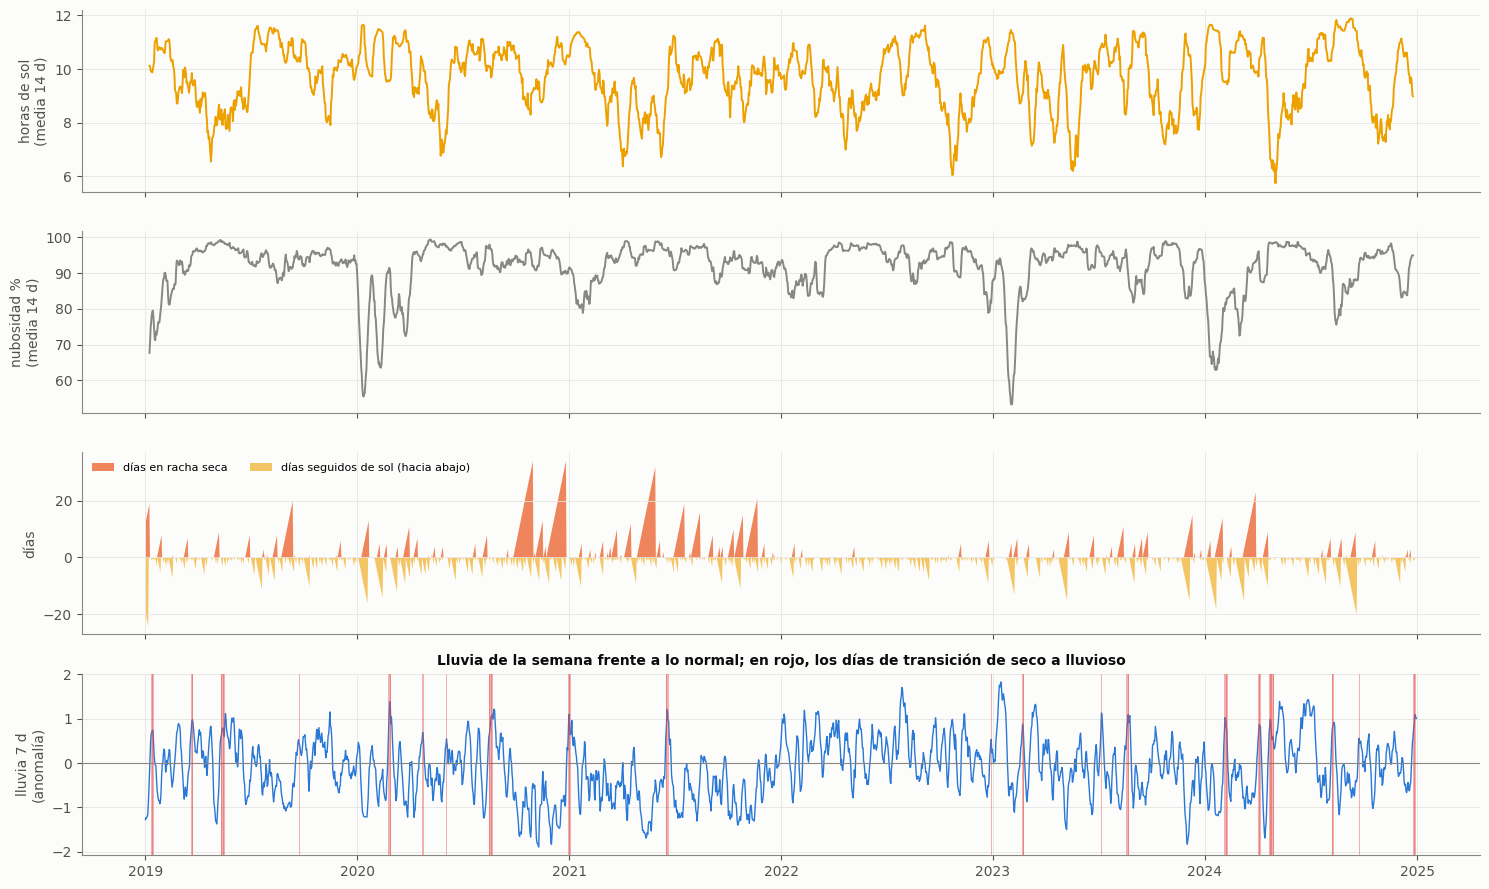

Horas de sol por mes (media diaria): {1: 10.4, 2: 10.0, 3: 9.4, 4: 8.2, 5: 8.3, 6: 9.7, 7: 10.2, 8: 10.6, 9: 10.2, 10: 8.6, 11: 8.7, 12: 9.9}
Nubosidad por mes (%): {1: 81.0, 2: 86.0, 3: 91.0, 4: 96.0, 5: 97.0, 6: 96.0, 7: 95.0, 8: 93.0, 9: 93.0, 10: 96.0, 11: 95.0, 12: 88.0}
Racha seca más larga por año (días): {2010: 13, 2011: 7, 2012: 8, 2013: 3, 2014: 17, 2015: 33, 2016: 37, 2017: 27, 2018: 12, 2019: 20, 2020: 34, 2021: 32, 2022: 6, 2023: 15, 2024: 23}
Días de transición seco → lluvioso por año: {2010: 4, 2011: 4, 2012: 4, 2013: 0, 2014: 1, 2015: 6, 2016: 7, 2017: 11, 2018: 10, 2019: 14, 2020: 15, 2021: 6, 2022: 1, 2023: 8, 2024: 25}


In [2]:
v = cc.loc["2019-01-01":FIN_EXPLORA]
fig, axes = plt.subplots(4, 1, figsize=(15, 9), sharex=True)
axes[0].plot(v.index, v.horas_sol.rolling(14, center=True).mean(), color=AMARILLO, lw=1.4); axes[0].set_ylabel("horas de sol\n(media 14 d)")
axes[1].plot(v.index, v.cloud_cover_mean.rolling(14, center=True).mean(), color=MUDO, lw=1.4); axes[1].set_ylabel("nubosidad %\n(media 14 d)")
axes[2].fill_between(v.index, 0, v.dias_en_racha_seca, color=NARANJA, lw=0, alpha=.8, label="días en racha seca")
axes[2].fill_between(v.index, 0, -v.dias_de_sol.clip(upper=30), color=AMARILLO, lw=0, alpha=.6, label="días seguidos de sol (hacia abajo)")
axes[2].legend(loc="upper left", fontsize=8, ncol=2); axes[2].set_ylabel("días")
axes[3].plot(v.index, v.lluvia_7d, color=AZUL, lw=1); axes[3].axhline(0, color=MUDO, lw=.8)
for d in v.index[v.seco_a_lluvioso > 0]: axes[3].axvline(d, color=ROJO, lw=.6, alpha=.5)
axes[3].set_ylabel("lluvia 7 d\n(anomalía)"); axes[3].set_title("Lluvia de la semana frente a lo normal; en rojo, los días de transición de seco a lluvioso", fontsize=10)
plt.tight_layout(); plt.show()
mes = cc.loc[:FIN_EXPLORA].groupby(cc.loc[:FIN_EXPLORA].index.month)
print("Horas de sol por mes (media diaria):", mes.horas_sol.mean().round(1).to_dict())
print("Nubosidad por mes (%):", mes.cloud_cover_mean.mean().round(0).to_dict())
print("Racha seca más larga por año (días):", cc.dias_en_racha_seca.groupby(cc.index.year).max().loc[2010:2024].astype(int).to_dict())
print("Días de transición seco → lluvioso por año:", cc.seco_a_lluvioso.groupby(cc.index.year).sum().astype(int).loc[:2024].to_dict())

**Lectura.** La figura muestra cuatro de las variables nuevas entre 2019 y 2024.

- **Sol y nubosidad tienen una estación definida.** Entre 2010 y 2024 la media diaria es de 10,4 y 10,0 horas de sol en enero y febrero, y de 10,2 a 10,6 de julio a septiembre; baja a 8,2-8,3 en abril y mayo y a 8,6-8,7 en octubre y noviembre. La nubosidad media pasa del 81-86 % en enero-febrero al 96-97 % en abril-junio. Coincide con los dos periodos lluviosos de la región.
- **Las rachas secas largas aparecen en los años de El Niño y en el periodo 2020-2021.** La racha más larga de cada año fue de 33 días en 2015, 37 en 2016, 34 en 2020 y 32 en 2021, frente a 15 en 2023 y 23 en 2024.
- **La transición de seco a lluvioso es un evento raro.** Hubo 0 días marcados en 2013, 1 en 2014 y en 2022, y como máximo 15 en cualquiera de los demás años; **2024 tiene 25**, el máximo de la serie. Esta es la variable que codifica el giro y no el nivel, y su escasez es el límite principal de lo que se puede concluir sobre ella (sección 6).

---
# 2. Los tres desenlaces

In [3]:
v = pd.read_csv(RAIZ / "calendarios/vigilancia_sivigila.csv.gz", parse_dates=["fecha_inicio_semana"])
ira = (v[(v.ambito == "manizales") & (v.evento == 995) & (v.variable == "consultas_ira_total")]
         .drop_duplicates("fecha_inicio_semana").set_index("fecha_inicio_semana").valor.astype(float))
ira = np.log(ira.loc["2012-01-01":FIN_EXPLORA]); ira[(ira.index >= "2020-03-15") & (ira.index <= "2021-12-31")] = np.nan
dx = pd.read_parquet(RAIZ / "salidas/perfil_dx_diario.parquet"); dx["dia"] = pd.to_datetime(dx.dia)
resp = dx[dx.capitulo == "X Respiratorio"].set_index("dia").n.reindex(pd.date_range("2020-01-01", FIN_EXPLORA)).fillna(0)
resp = np.log1p(semana(resp, "sum")).loc["2021-01-01":FIN_EXPLORA]
tot = desenlace_semanal().y.loc[:FIN_EXPLORA]
DES = {"IRA de Manizales": ira, "ingresos respiratorios del hospital": resp, "triage total (sin calendario ni red)": tot}
for k, s in DES.items(): print(f"{k}: {s.notna().sum()} semanas, {s.dropna().index[0].date()} a {s.dropna().index[-1].date()}")
print(f"Media semanal en la ventana: IRA de Manizales {np.exp(ira).mean():,.0f} consultas; ingresos respiratorios {np.expm1(resp).mean():.1f}; triage total {tot.index.size and desenlace_semanal().triage.loc[:FIN_EXPLORA].mean():,.0f}")

IRA de Manizales: 585 semanas, 2012-01-01 a 2024-12-29
ingresos respiratorios del hospital: 209 semanas, 2021-01-03 a 2024-12-29
triage total (sin calendario ni red): 147 semanas, 2022-03-06 a 2024-12-29
Media semanal en la ventana: IRA de Manizales 1,346 consultas; ingresos respiratorios 39.4; triage total 1,430


---
# 3. El barrido de cada variable de clima con rezago de 0 a 6 semanas

Por cada desenlace, variable y rezago: `desenlace(semana t) ~ clima(semana t − rezago) + mes + año`. El
efecto se lee como **% de cambio en el desenlace por cada desviación típica de la variable**, con errores HAC.

In [4]:
def barrido(y, X, rezagos=range(0, 7)):
    filas = []
    idx = y.dropna().index
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    anio = pd.get_dummies(pd.Index(idx.year), prefix="a", drop_first=True).set_index(idx).astype(float)
    for c in X:
        xs = (X[c] - X[c].loc[:FIN_EXPLORA].mean()) / X[c].loc[:FIN_EXPLORA].std()
        for L in rezagos:
            D = pd.concat([y.rename("y"), xs.shift(L).rename("x"), mes, anio], axis=1).loc[idx].dropna()
            if len(D) < 60 or D.x.std() == 0: continue
            r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
            filas.append({"variable": c, "familia": FAMILIA[c], "rezago": L, "efecto %": 100 * (np.exp(r.params["x"]) - 1), "ee %": 100 * r.bse["x"], "p": r.pvalues["x"], "n": len(D)})
    T = pd.DataFrame(filas); T["q"] = multipletests(T.p, method="fdr_bh")[1]
    return T
RES = {k: barrido(s, F) for k, s in DES.items()}
resumen = pd.DataFrame({k: {"pruebas": len(T), "p < 0,05": int((T.p < .05).sum()), "azar esperaría": round(.05 * len(T)),
                            "sobreviven BH (q < 0,10)": int((T.q < .10).sum())} for k, T in RES.items()}).T
resumen

,pruebas,"p < 0,05",azar esperaría,"sobreviven BH (q < 0,10)"
IRA de Manizales,266,72,13,53
ingresos respiratorios del hospital,266,5,13,0
triage total (sin calendario ni red),266,63,13,36


**Lectura.** Los tres desenlaces responden de forma muy distinta, y la diferencia tiene explicación en el tamaño de cada serie.

1. **La IRA de la ciudad responde al clima con claridad.** De 266 pruebas, 72 tienen p < 0,05 cuando la cuenta ingenua del 5 % daría unas 13, y **53 sobreviven a BH**. La serie tiene 585 semanas y unas 1.346 consultas por semana.
2. **El triage total también responde, con efectos pequeños.** Sobreviven 36 de 266 pruebas (63 con p < 0,05), con efectos de 1,5 a 2,4 % por desviación típica, aunque ese número depende de una convención y no se separa del azar (ver el último párrafo).
3. **Los ingresos respiratorios del hospital no responden.** Solo 5 pruebas tienen p < 0,05, menos de las 13 que daría el azar, y ninguna sobrevive. Son unos 39 ingresos por semana en 2021-2024 y 209 semanas. En la sección 8 se mide qué efecto podía detectar un diseño con ese tamaño: **no se puede separar un efecto menor de unos 10 % del ruido**, de modo que este resultado nulo no descarta un efecto como el de la IRA.

**Calibración posterior del azar.** El cuaderno 12 repitió el barrido 300 veces con el desenlace desplazado en círculo y midió el azar real: alrededor del 10 % de las pruebas dan p < 0,05, no el 5 %, y el número de supervivientes está sobredispersado. Para la IRA de la ciudad la señal resiste esa calibración: sobreviven 47 pruebas frente a 0,75 esperadas por azar, y 7 se confirman en 2025 frente a 0,08. El «unas 13» de arriba es la cuenta ingenua del 5 %, y el azar real de los supervivientes a BH es mucho menor, de modo que la señal de la IRA queda incluso más fuerte. Para el triage total ocurre lo contrario: las 36 pruebas dependen de una convención. Tomando el mes de la semana a partir de su primer día salen 36, y tomándolo de la mitad de la semana salen 18, frente a 12,7 del azar (p empírico 0,24). En el total, por tanto, no se puede separar la señal del clima del azar ni de la fecha; eso no equivale a decir que el clima no afecte.

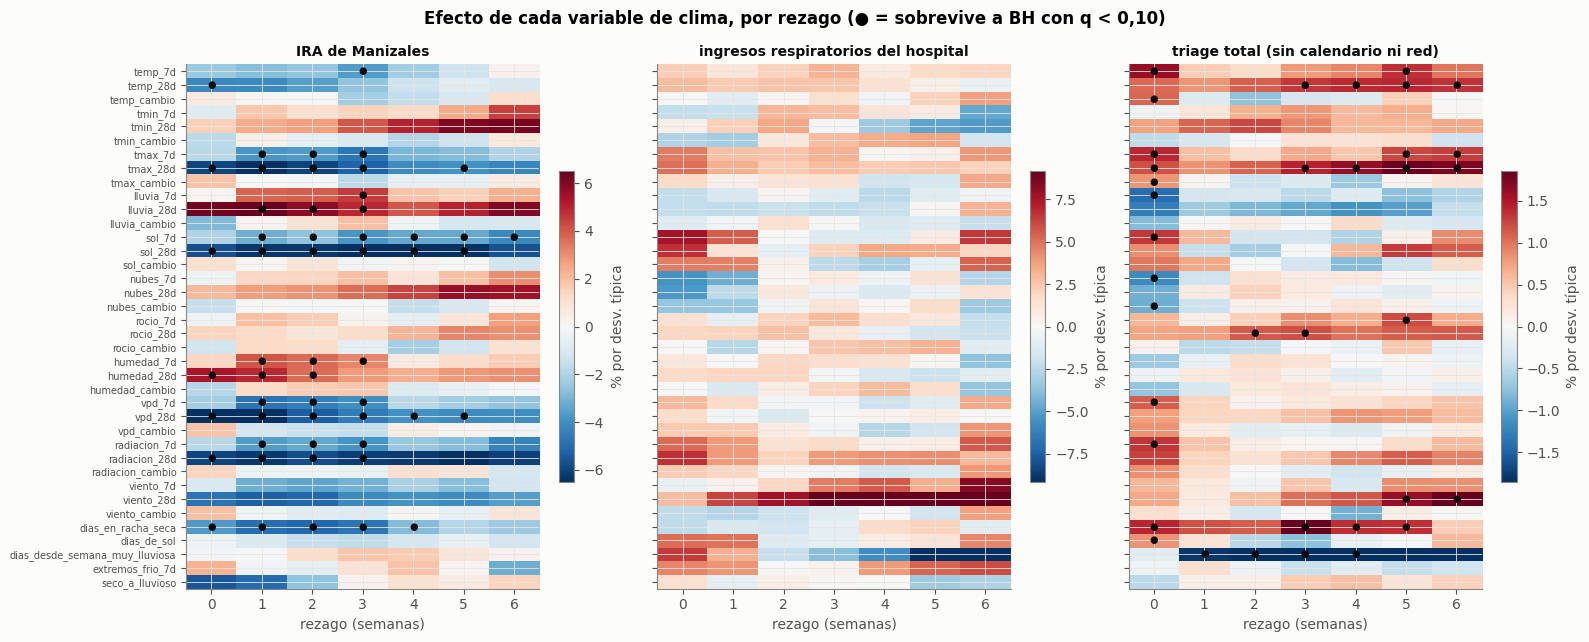

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 6.5), sharey=True)
orden = list(F.columns)
for ax, (k, T) in zip(axes, RES.items()):
    M = T.pivot_table(index="variable", columns="rezago", values="efecto %").reindex(orden)
    Q = T.pivot_table(index="variable", columns="rezago", values="q").reindex(orden)
    lim = np.nanpercentile(np.abs(M.values), 98)
    im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    for (i, j), q in np.ndenumerate(Q.values):
        if q < .10: ax.text(j, i, "●", ha="center", va="center", fontsize=7, color=TINTA)
    ax.set_xticks(range(M.shape[1]), M.columns); ax.set_xlabel("rezago (semanas)"); ax.set_title(k, fontsize=10)
    plt.colorbar(im, ax=ax, fraction=.04, label="% por desv. típica")
axes[0].set_yticks(range(len(orden)), orden, fontsize=7)
fig.suptitle("Efecto de cada variable de clima, por rezago (● = sobrevive a BH con q < 0,10)", fontweight="bold"); plt.tight_layout(); plt.show()

**Lectura.** La figura reúne los 266 efectos de cada desenlace. En la IRA (panel izquierdo) las franjas son horizontales: una misma variable tiene el mismo signo en rezagos de 0 a 5 semanas, y los puntos se agrupan en las variables de 28 días. Azul para sol, déficit de presión de vapor, radiación y temperatura máxima; rojo para lluvia y humedad. Es una sola configuración, **mes nublado, húmedo y con poco sol frente a mes soleado y de aire seco**, vista desde muchas variables correlacionadas, por lo que los 53 hallazgos no son 53 evidencias independientes (el primer componente del clima explica el 49 % de la varianza, sección 5). En el triage total (panel derecho) el patrón es otro: los puntos están en variables distintas (racha seca, calor del mes, días desde la última semana muy lluviosa) y con signos que no repiten los de la IRA. Los ingresos (panel central) no muestran puntos; la escala de color es la más ancha de las tres, porque los efectos estimados son más imprecisos.

In [6]:
top = []
for k, T in RES.items():
    t = T[T.q < .10].copy(); t["desenlace"] = k; top.append(t)
TOP = pd.concat(top) if top else pd.DataFrame()
print("Lo que sobrevive a BH, ordenado por tamaño del efecto dentro de cada desenlace:")
(TOP.assign(abs_=TOP["efecto %"].abs()).sort_values(["desenlace", "abs_"], ascending=[True, False])
    .groupby("desenlace").head(12)[["desenlace", "variable", "familia", "rezago", "efecto %", "q", "n"]].round(3)) if len(TOP) else "nada sobrevive"

Lo que sobrevive a BH, ordenado por tamaño del efecto dentro de cada desenlace:


,desenlace,variable,familia,rezago,efecto %,q,n
71,IRA de Manizales,lluvia_28d,nivel 28 días,1,7.049,0.088,585
94,IRA de Manizales,sol_28d,nivel 28 días,3,-6.976,0.013,585
95,IRA de Manizales,sol_28d,nivel 28 días,4,-6.864,0.023,585
175,IRA de Manizales,vpd_28d,nivel 28 días,0,-6.676,0.002,585
176,IRA de Manizales,vpd_28d,nivel 28 días,1,-6.512,0.002,585
50,IRA de Manizales,tmax_28d,nivel 28 días,1,-6.484,0.013,585
96,IRA de Manizales,sol_28d,nivel 28 días,5,-6.428,0.053,585
92,IRA de Manizales,sol_28d,nivel 28 días,1,-6.333,0.009,585
197,IRA de Manizales,radiacion_28d,nivel 28 días,1,-6.275,0.013,585
93,IRA de Manizales,sol_28d,nivel 28 días,2,-6.262,0.009,585


**Lectura.**

- **Para la IRA de la ciudad el patrón es coherente.** Un mes lluvioso, nublado, húmedo y con poco sol se asocia con **6-7 % más IRA** de 1 a 5 semanas después, por cada desviación típica:
  - lluvia de 28 días, +7,0 % a 1 semana (q = 0,088, el más débil de la lista);
  - horas de sol de 28 días, −7,0 % a 3 semanas;
  - déficit de presión de vapor de 28 días (aire seco), −6,7 % a 0 semanas;
  - temperatura máxima de 28 días, −6,5 % a 1 semana;
  - radiación de 28 días, −6,3 % a 1 semana.

  Coincide con el frío y la humedad del último mes del cuaderno 11, con horas de sol y sequedad del aire como piezas nuevas. En Bogotá, el análogo más cercano en la literatura, dos series de niños menores de 3 años hospitalizados por infección respiratoria baja asocian el virus sincitial respiratorio con la lluvia (Rodriguez-Martinez et al., 2015, doi:10.1017/S0950268814003793; Gamba-Sanchez et al., 2016, doi:10.1017/S0950268816000273), aunque a escala mensual y sin rezagos.
- **Para el triage total los efectos son pequeños y de otro tipo.** Cuanto más lejos está la última semana muy lluviosa, menos triage (−2,4 % a 2-4 semanas); una racha seca larga lo sube (+2,1 % a 3 semanas); el calor y el viento del último mes lo suben (+1,6 a +1,8 % a 4-6 semanas).
- **La escala temporal que importa es el mes** (28 días) y no la semana, lo que concuerda con un mecanismo de contagio y con el rezago de días a semanas.

---
# 4. Aporte de las variables nuevas

Se separan las que ya existían en el modelo (temperatura, humedad, lluvia, radiación y viento en nivel) de las
que se crearon para este cuaderno: horas de sol, nubosidad, punto de rocío, déficit de presión de vapor, los cambios
bruscos, las rachas, los extremos y la transición.

In [7]:
NUEVAS = lambda c: (c.split("_")[0] in ["sol", "nubes", "rocio", "vpd"]) or c.endswith("_cambio") or FAMILIA[c] == "racha / extremo / transición"
filas = []
for k, T in RES.items():
    for grupo, sel in [("ya existían (niveles)", ~T.variable.map(NUEVAS)), ("nuevas", T.variable.map(NUEVAS))]:
        t = T[sel]; filas.append({"desenlace": k, "grupo": grupo, "pruebas": len(t), "sobreviven BH": int((t.q < .10).sum()),
                                  "% que sobrevive": round(100 * (t.q < .10).mean(), 1), "mayor efecto %": round(t.loc[t.q < .10, "efecto %"].abs().max(), 1) if (t.q < .10).any() else np.nan})
pd.DataFrame(filas).set_index(["desenlace", "grupo"])

pruebas  \
desenlace                            grupo                            
IRA de Manizales                     ya existían (niveles)       98   
                                     nuevas                     168   
ingresos respiratorios del hospital  ya existían (niveles)       98   
                                     nuevas                     168   
triage total (sin calendario ni red) ya existían (niveles)       98   
                                     nuevas                     168   

                                                            sobreviven BH  \
desenlace                            grupo                                  
IRA de Manizales                     ya existían (niveles)             27   
                                     nuevas                            26   
ingresos respiratorios del hospital  ya existían (niveles)              0   
                                     nuevas                             0   
triage total (sin calendario ni red) ya existían (niveles)             18   
                                     nuevas                            18   

                                                            % que sobrevive  \
desenlace                            grupo                                    
IRA de Manizales                     ya existían (niveles)             27.6   
                                     nuevas                            15.5   
ingresos respiratorios del hospital  ya existían (niveles)              0.0   
                                     nuevas                             0.0   
triage total (sin calendario ni red) ya existían (niveles)             18.4   
                                     nuevas                            10.7   

                                                            mayor efecto %  
desenlace                            grupo                                  
IRA de Manizales                     ya existían (niveles)             7.0  
                                     nuevas                            7.0  
ingresos respiratorios del hospital  ya existían (niveles)             NaN  
                                     nuevas                            NaN  
triage total (sin calendario ni red) ya existían (niveles)             1.8  
                                     nuevas                            2.4

**Lectura.**

- **Las variables nuevas aportan, pero no reemplazan a las que ya existían.** En la IRA sobreviven 26 de 168 pruebas con variables nuevas (15,5 %) y 27 de 98 con las que ya existían (27,6 %). En el triage total, 18 de 168 (10,7 %) y 18 de 98 (18,4 %). El efecto máximo de la IRA es 7,0 % en los dos grupos, y entre las nuevas están dos de las más fuertes: horas de sol y déficit de presión de vapor, ambas a 28 días.
- **La transición de seco a lluvioso no produce ninguna prueba que sobreviva** (ver abajo el conteo). Con 0 a 25 días al año es un evento raro, y con pocos ejemplos el barrido semanal no tiene potencia para verla; la sección 6 la mira episodio por episodio.
- **En el triage total**, las rachas (días desde una semana muy lluviosa, días en racha seca) están entre lo que sobrevive.

In [8]:
print("Pruebas con la transición de seco a lluvioso que sobreviven a BH:", {k: int(((T.variable == "seco_a_lluvioso") & (T.q < .10)).sum()) for k, T in RES.items()})
pd.DataFrame({k: T[T.q < .10].groupby("familia").size() for k, T in RES.items()}).reindex(["nivel 7 días", "nivel 28 días", "cambio brusco", "racha / extremo / transición"]).fillna(0).astype(int)

Pruebas con la transición de seco a lluvioso que sobreviven a BH: {'IRA de Manizales': 0, 'ingresos respiratorios del hospital': 0, 'triage total (sin calendario ni red)': 0}


,IRA de Manizales,ingresos respiratorios del hospital,triage total (sin calendario ni red)
familia,,,
nivel 7 días,20,0,11
nivel 28 días,28,0,13
cambio brusco,0,0,3
racha / extremo / transición,5,0,9


**Lectura.** La tabla cuenta las pruebas que sobreviven a BH por familia de variable. En la IRA, 48 de las 53 son niveles (20 de 7 días y 28 de 28 días), 5 son rachas o extremos y **ninguna es un cambio brusco**. En el triage total, 24 de las 36 son niveles, 9 son rachas o extremos y 3 son cambios bruscos. La transición de seco a lluvioso no tiene ninguna prueba que sobreviva en ninguno de los tres desenlaces. Cuando se mira el clima semana a semana, **lo que pesa es la exposición acumulada y no el giro**.

---
# 5. Índices que resumen el clima en pocas cifras

Para no darle al modelo 40 variables sueltas, que en el cuaderno 15 sobreajustaron el modelo, se resumen en
**componentes principales**, ajustados solo con 2010-2024:
- el **«estado del clima»**: los niveles de 7 días;
- el **«cambio brusco»**: los cambios.

In [9]:
from sklearn.decomposition import PCA
def indices(cols, k, nombre):
    Z = F[cols].loc["2010-01-10":FIN_EXPLORA].dropna(); mu, sd = Z.mean(), Z.std()
    p = PCA(k).fit((Z - mu) / sd)
    S = pd.DataFrame(p.transform(((F[cols] - mu) / sd).dropna()), index=F[cols].dropna().index, columns=[f"{nombre}_{i + 1}" for i in range(k)])
    L = pd.DataFrame(p.components_.T, index=cols, columns=S.columns).round(2)
    return S, L, p.explained_variance_ratio_
S1, L1, v1 = indices([f"{n}_7d" for n in NIVELES], 4, "estado")
S2, L2, v2 = indices([f"{n}_cambio" for n in NIVELES], 3, "cambio")
print(f"Estado del clima: 4 componentes explican {v1.sum():.0%} ({np.round(v1, 2)}); cambio brusco: 3 explican {v2.sum():.0%} ({np.round(v2, 2)})")
display(pd.concat([L1, L2], axis=1).fillna(""))
IDX = S1.join(S2, how="outer")
FAMILIA.update({c: "índice" for c in IDX})
RI = {k: barrido(s, IDX) for k, s in DES.items()}
pd.concat({k: T[T.q < .10][["variable", "rezago", "efecto %", "q"]] for k, T in RI.items()}).round(3)

Estado del clima: 4 componentes explican 86% ([0.49 0.22 0.09 0.07]); cambio brusco: 3 explican 81% ([0.54 0.19 0.08])


,estado_1,estado_2,estado_3,estado_4,cambio_1,cambio_2,cambio_3
temp_7d,0.19,0.56,-0.05,-0.14,,,
tmin_7d,-0.18,0.47,-0.32,-0.14,,,
tmax_7d,0.33,0.35,0.09,0.06,,,
lluvia_7d,-0.29,-0.07,-0.34,-0.03,,,
sol_7d,0.32,-0.07,-0.32,0.61,,,
nubes_7d,-0.32,0.1,0.32,0.06,,,
rocio_7d,-0.16,0.56,0.08,0.29,,,
humedad_7d,-0.37,0.05,0.14,0.49,,,
vpd_7d,0.4,0.05,-0.08,-0.34,,,
radiacion_7d,0.39,-0.04,-0.11,0.38,,,


variable  rezago  efecto %      q
IRA de Manizales                     1   estado_1       1    -4.117  0.061
                                     2   estado_1       2    -3.841  0.034
                                     3   estado_1       3    -4.146  0.021
triage total (sin calendario ni red) 0   estado_1       0     1.276  0.026
                                     12  estado_2       5     1.440  0.026

**Lectura.**

- **El clima de Manizales cabe en pocas cifras.** Cuatro componentes resumen el 86 % de la varianza de los once niveles semanales:
  - **estado_1** (49 %), «semana soleada, seca y de aire seco» frente a «semana nublada, húmeda y lluviosa»;
  - **estado_2** (22 %), temperatura y punto de rocío: semana cálida y bochornosa;
  - **estado_3** (9 %), viento;
  - **estado_4** (7 %), sol con humedad.
- Tres componentes resumen el 81 % de los cambios bruscos.
- **Con un solo índice, estado_1, se recupera lo esencial en la IRA:** −4 % por desviación típica a 1-3 semanas (q entre 0,02 y 0,06). En el triage total estado_1 tiene +1,3 % en la misma semana, es decir, **con el signo contrario**; ese desacuerdo de signo reaparece en la sección 8. Ningún índice de cambio brusco sobrevive.
- Dar al modelo 4 + 3 índices en lugar de 38 variables reduce la redundancia que sobreajustó el cuaderno 15.

---
# 6. Episodios concretos de transición de seco a lluvioso

Un promedio de 13 años puede diluir un efecto que ocurre solo en los giros bruscos. Por eso se miran las
transiciones una por una. El indicador marca un día cuando las dos semanas previas fueron secas y la lluvia de la
última semana supera lo normal; los días marcados a menos de 14 días uno de otro se agrupan en un **episodio**.
Para cada episodio se toma la semana en que empieza como semana 0 y se sigue el desenlace tres semanas antes y
seis después, siempre como desvío frente a lo esperado para ese mes y año. Como referencia, se repite el cálculo
2.000 veces con el mismo número de semanas escogidas al azar: la banda gris es el rango en que caería el promedio
de episodios si la fecha no importara.

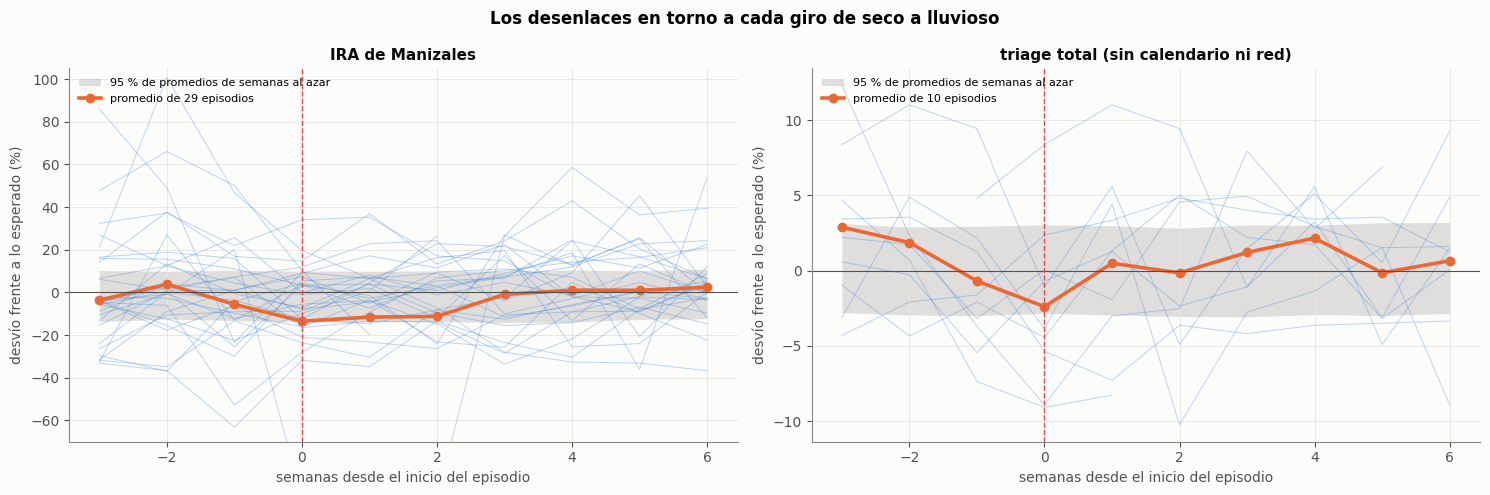

Primer día de cada episodio: 2010-10-29, 2011-05-27, 2011-07-16, 2011-09-19, 2012-08-02, 2014-09-16, 2015-01-20, 2015-10-16, 2016-04-05, 2016-07-17, 2016-08-14, 2017-06-11, 2017-07-19, 2017-08-12, 2017-10-26, 2017-12-31, 2018-03-24, 2018-05-08, 2019-01-11, 2019-03-21, 2019-05-11, 2019-09-22, 2020-02-24, 2020-04-22, 2020-06-03, 2020-08-15, 2020-12-30, 2021-06-16, 2022-12-29, 2023-02-20, 2023-07-07, 2023-08-19, 2024-02-04, 2024-04-02, 2024-04-21, 2024-08-07, 2024-09-23, 2024-12-25


,episodios,desvío medio semanas 1-4 (%),mediana semanas 1-4 (%),episodios con desvío > 0,percentil frente al azar,rebote semanas 3-6 menos -1-2 (puntos %),percentil del rebote,mediana del rebote (puntos %),episodios con rebote > 0
desenlace,,,,,,,,,
IRA de Manizales,29,-6.11,2.48,16,10.5,12.86,98.2,2.21,17
triage total (sin calendario ni red),10,0.19,1.46,7,59.0,1.15,81.6,0.83,7


In [10]:
sl = cc.seco_a_lluvioso.loc[:FIN_EXPLORA]; EP = []
for d in sl.index[sl > 0]:
    if not EP or (d - EP[-1][-1]).days > 14: EP.append([d])
    else: EP[-1].append(d)
ini = pd.DatetimeIndex([e[0] for e in EP]); ini_sem = ini - pd.to_timedelta((ini.weekday + 1) % 7, unit="D")
def sin_estacion(y):
    y = y.dropna()
    X = pd.concat([pd.get_dummies(pd.Index(y.index.month), prefix="m", drop_first=True),
                   pd.get_dummies(pd.Index(y.index.year), prefix="a", drop_first=True)], axis=1).set_index(y.index).astype(float)
    return sm.OLS(y, sm.add_constant(X)).fit().resid
OFS = list(range(-3, 7)); rng = np.random.default_rng(17)
def camino(y):
    r = sin_estacion(y).reindex(pd.date_range(y.index.min(), y.index.max(), freq="W-SUN"))
    M = pd.DataFrame({k: r.shift(-k) for k in OFS})
    E = M.reindex(ini_sem).dropna(how="all"); E = E[E[0].notna()]
    valido = M[M[0].notna()].values
    sim = np.array([np.nanmean(valido[rng.choice(len(valido), len(E), replace=False)], axis=0) for _ in range(2000)])
    return E, sim
EPI = {k: camino(DES[k]) for k in ["IRA de Manizales", "triage total (sin calendario ni red)"]}
pc = lambda x: 100 * (np.exp(x) - 1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
for ax, (k, (E, sim)) in zip(axes, EPI.items()):
    lo, hi = np.nanpercentile(sim, [2.5, 97.5], axis=0)
    ax.fill_between(OFS, pc(lo), pc(hi), color=MUDO, alpha=.25, lw=0, label="95 % de promedios de semanas al azar")
    for _, f in E.iterrows(): ax.plot(OFS, pc(f.values), color=AZUL, lw=.7, alpha=.3)
    ax.plot(OFS, pc(E.mean().values), color=NARANJA, lw=2.6, marker="o", label=f"promedio de {len(E)} episodios")
    ax.axhline(0, color=TINTA2, lw=.8); ax.axvline(0, color=ROJO, lw=1, ls="--")
    ax.set_xlabel("semanas desde el inicio del episodio"); ax.set_ylabel("desvío frente a lo esperado (%)")
    ax.set_title(k); ax.legend(loc="upper left", fontsize=8)
    if k.startswith("IRA"): ax.set_ylim(-70, 105)
fig.suptitle("Los desenlaces en torno a cada giro de seco a lluvioso", fontweight="bold"); plt.tight_layout(); plt.show()
filas = []
for k, (E, sim) in EPI.items():
    ventana = E[[1, 2, 3, 4]].mean(axis=1); sv = sim[:, [OFS.index(j) for j in (1, 2, 3, 4)]].mean(axis=1)
    rebote = E[[3, 4, 5, 6]].mean(axis=1) - E[[-1, 0, 1, 2]].mean(axis=1)
    sr = sim[:, [OFS.index(j) for j in (3, 4, 5, 6)]].mean(axis=1) - sim[:, [OFS.index(j) for j in (-1, 0, 1, 2)]].mean(axis=1)
    filas.append({"desenlace": k, "episodios": len(E), "desvío medio semanas 1-4 (%)": round(pc(ventana.mean()), 2),
                  "mediana semanas 1-4 (%)": round(pc(ventana.median()), 2), "episodios con desvío > 0": int((ventana > 0).sum()),
                  "percentil frente al azar": round(100 * (sv < ventana.mean()).mean(), 1),
                  "rebote semanas 3-6 menos -1-2 (puntos %)": round(100 * rebote.mean(), 2), "percentil del rebote": round(100 * (sr < rebote.mean()).mean(), 1),
                  "mediana del rebote (puntos %)": round(100 * rebote.median(), 2), "episodios con rebote > 0": int((rebote > 0).sum())})
print("Primer día de cada episodio:", ", ".join(d.strftime("%Y-%m-%d") for d in ini))
pd.DataFrame(filas).set_index("desenlace")

**Lectura.** Cada línea azul es un episodio; la naranja, el promedio, y la banda gris, lo que daría un promedio de semanas elegidas al azar.

- **IRA de la ciudad (29 episodios con datos).** El desvío medio de las semanas 1 a 4 es de −6,1 %, pero la mediana es de +2,5 % y solo 16 de 29 episodios son positivos. La media la arrastra un episodio de 2012 (semana del 29 de julio, −74,8 % en el promedio de las semanas 1-4, y cerca de −96 % en las semanas 0 a 2, por lo que su línea sale por debajo del recuadro de la figura) y su percentil frente al azar es 10,5: **no se distingue de lo que producirían semanas cualquiera**. El promedio sí muestra una forma: la IRA está entre un 11 y un 13 % por debajo de lo normal en las semanas 0 a 2, justo al terminar la racha seca y empezar la lluvia, y vuelve a lo normal desde la semana 3. El contraste entre las semanas 3-6 y las semanas −1 a 2 es de +12,9 puntos y cae en el percentil 98,2, pero esta ventana se eligió después de ver la curva y el resultado depende de ese mismo episodio de 2012: su mediana es de +2,2 puntos y 17 de 29 episodios son positivos. **Es una pista, no un hallazgo.**
- **Triage total (10 episodios, 2022-2024).** El desvío medio es de +0,2 %, la mediana de +1,5 %, 7 de 10 episodios son positivos y el percentil frente al azar es 59. La banda del azar es de unos ±3 %, mayor que los efectos de 1,5 a 2,4 % hallados en el barrido; con 10 episodios **este diseño no podía ver un efecto de ese tamaño**. Tampoco se debe leer como ausencia de efecto: el último episodio (22 de diciembre de 2024) solo tiene una de sus cuatro semanas, porque la serie se corta el 29 de diciembre.

In [11]:
E_ira = EPI["IRA de Manizales"][0]; E_tot = EPI["triage total (sin calendario ni red)"][0]
T = pd.DataFrame({"IRA, desvío semanas 1-4 (%)": pc(E_ira[[1, 2, 3, 4]].mean(axis=1)).round(1),
                  "días del episodio": pd.Series({s: len(e) for s, e in zip(ini_sem, EP)}),
                  "triage total, desvío semanas 1-4 (%)": pc(E_tot[[1, 2, 3, 4]].mean(axis=1)).round(1)})
T.index = T.index.strftime("%Y-%m-%d"); T.index.name = "semana de inicio"; T.dropna(subset=["IRA, desvío semanas 1-4 (%)"]).astype(object).fillna("sin dato")

,"IRA, desvío semanas 1-4 (%)",días del episodio,"triage total, desvío semanas 1-4 (%)"
semana de inicio,,,
2012-07-29,-74.8,4,sin dato
2014-09-14,-16.7,1,sin dato
2015-01-18,6.7,4,sin dato
2015-10-11,28.7,2,sin dato
2016-04-03,6.4,1,sin dato
2016-07-17,4.0,2,sin dato
2016-08-14,7.4,4,sin dato
2017-06-11,-17.7,4,sin dato
2017-07-16,7.5,2,sin dato


**Lectura.** En la IRA, los mayores aumentos tras el giro fueron en octubre de 2015 (+28,7 %), agosto de 2024 (+15,5 %) y febrero de 2023 (+15,3 %), y las mayores caídas, julio de 2012 (−74,8 %), marzo de 2024 (−26,0 %) y diciembre de 2024 (−19,7 %). En 2024, el año con más días de transición, la IRA cayó tras 5 de los 6 episodios, mientras que el triage total subió tras 4 de ellos (+1,2, +6,1, +1,7 y +3,9 %) y bajó tras los dos últimos (−4,7 y −8,3 %). La irregularidad de los signos es lo que muestra la tabla: **el giro de seco a lluvioso no produce un mismo desvío cada vez**, y entender por qué unos episodios suben y otros no (la duración de la racha previa, la intensidad de la lluvia, el estado de la epidemia) exigiría más episodios de los que hay.

---
# 7. El clima por banda de edad

Si el efecto respiratorio del clima es grande en los niños y en los mayores y casi nulo en los adultos jóvenes, el
total lo promedia y lo apaga. Se repite el barrido con cada banda de edad del triage (0-4, 5-14, 15-44, 45-64 y
65 o más años) como desenlace, de 2022-03 a 2024-12. Cada banda se lleva a su residuo semanal sin calendario, sin
nivel del año y sin escalones de la red, conservando la estación. Las variables son los siete índices de clima,
las rachas, los extremos y la transición de seco a lluvioso, a rezagos de 0 a 4 semanas, con mes fijo, errores HAC
y BH por banda.

In [12]:
dias = pd.date_range("2020-01-01", "2026-09-20")
ed = pd.read_parquet(RAIZ / "salidas/triage_edad.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
E = ed.pivot_table(index="dia", columns="banda", values="n", aggfunc="sum").reindex(dias).fillna(0)
nv = pd.read_parquet(RAIZ / "salidas/triage_nivel.parquet").assign(dia=lambda d: pd.to_datetime(d.dia))
P = pd.DataFrame({"0-4": E["0-4"], "5-14": E["5-14"], "15-44": E["15-44"], "45-64": E["45-64"], "65+": E["65-+"],
                  "total": nv.groupby("dia").n.sum().reindex(dias).fillna(0)})
P.loc["2024-03-19":"2024-03-21"] = np.nan
cal = (pd.read_csv(RAIZ / "calendarios/calendario_Colombia.csv", parse_dates=["fecha"]).set_index("fecha")
         .reindex(dias)[de.CAL].apply(pd.to_numeric, errors="coerce").fillna(0))
completas = de._semana(P["total"].notna().astype(int)) == 7
cal_w = de._semana(cal).loc[de.INICIO:"2024-12-29"]
RB = pd.DataFrame({c: de._residuo(de._semana(P[c]).where(completas).loc[de.INICIO:"2024-12-29"], cal_w) for c in P})
EXTRA = ["dias_en_racha_seca", "dias_de_sol", "dias_desde_semana_muy_lluviosa", "seco_a_lluvioso", "extremos_frio_7d"]
COL = list(IDX.columns) + EXTRA
XB = pd.concat([IDX, F[EXTRA]], axis=1)
def barrido_banda(y, rezagos=range(0, 5)):
    idx = y.dropna().index; filas = []
    mes = pd.get_dummies(pd.Index(idx.month), prefix="m", drop_first=True).set_index(idx).astype(float)
    for c in COL:
        xs = (XB[c] - XB[c].loc[:FIN_EXPLORA].mean()) / XB[c].loc[:FIN_EXPLORA].std()
        for L in rezagos:
            D = pd.concat([y.rename("y"), xs.shift(L).rename("x"), mes], axis=1).loc[idx].dropna()
            if len(D) < 60 or D.x.std() == 0: continue
            r = sm.OLS(D.y, sm.add_constant(D.drop(columns="y"))).fit(cov_type="HAC", cov_kwds={"maxlags": 4})
            filas.append({"variable": c, "rezago": L, "efecto %": 100 * (np.exp(r.params["x"]) - 1), "ee %": 100 * r.bse["x"],
                          "ic_bajo": 100 * (np.exp(r.params["x"] - 1.96 * r.bse["x"]) - 1), "ic_alto": 100 * (np.exp(r.params["x"] + 1.96 * r.bse["x"]) - 1),
                          "p": r.pvalues["x"]})
    T = pd.DataFrame(filas); T["q"] = multipletests(T.p, method="fdr_bh")[1]; return T
TB = {c: barrido_banda(RB[c]) for c in RB}
peso = (P.loc["2022":"2024"].mean() / P.loc["2022":"2024", "total"].mean() * 100).round(1)
res = pd.DataFrame({c: {"peso en el triage %": peso[c], "pruebas": len(T), "p < 0,05": int((T.p < .05).sum()), "sobreviven BH": int((T.q < .10).sum()),
                        "mayor efecto que sobrevive %": round(T.loc[T.q < .10, "efecto %"].abs().max(), 1) if (T.q < .10).any() else np.nan,
                        "ruido semanal del residuo %": round(100 * RB[c].std(), 1)} for c, T in TB.items()}).T
res

,peso en el triage %,pruebas,"p < 0,05",sobreviven BH,mayor efecto que sobrevive %,ruido semanal del residuo %
0-4,3.0,60.0,10.0,1.0,7.7,26.0
5-14,4.4,60.0,6.0,0.0,NaN,23.0
15-44,55.3,60.0,11.0,3.0,2.8,6.6
45-64,18.4,60.0,9.0,4.0,3.0,8.5
65+,18.8,60.0,9.0,7.0,4.6,9.1
total,100.0,60.0,12.0,7.0,2.1,6.0


**Lectura.**

- **El efecto máximo que sobrevive es mayor en las bandas pequeñas.** 7,7 % en 0-4 años, 4,6 % en 65 o más, 3,0 % en 45-64, 2,8 % en 15-44 y 2,1 % en el total, todos del periodo de descubrimiento (no se confirman en 2025-2026; cuaderno 21).
- **Las bandas pediátricas son muy ruidosas.** El residuo semanal varía un 26 % en 0-4 años y un 23 % en 5-14, contra el 6,0 % del total, porque son 3 y 4 % del triage. Por eso, con efectos grandes, sobrevive solo 1 prueba en 0-4 y ninguna en 5-14.
- **Las bandas de adultos y mayores acumulan los hallazgos:** 3 pruebas en 15-44, 4 en 45-64 y 7 en 65 o más, contra 7 en el total.
- Cada banda se contrasta con 60 pruebas, de modo que el número de hallazgos por banda es comparable entre ellas pero no con el barrido de la sección 3.

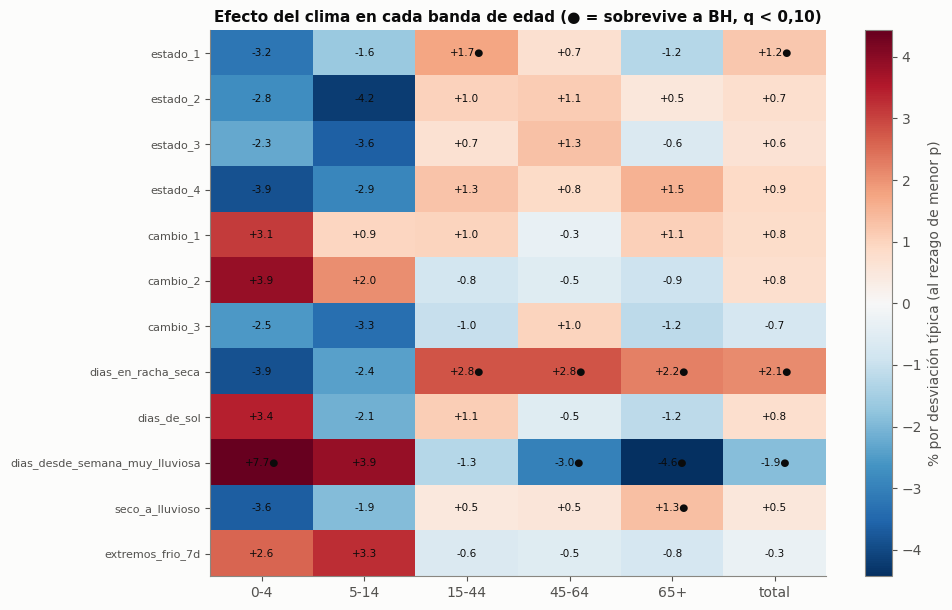

In [13]:
cel = {c: T.loc[T.groupby("variable").p.idxmin()].set_index("variable") for c, T in TB.items()}
M = pd.DataFrame({c: cel[c]["efecto %"] for c in cel}).reindex(COL); Q = pd.DataFrame({c: cel[c]["q"] for c in cel}).reindex(COL)
fig, ax = plt.subplots(figsize=(10, 6.2)); lim = np.nanpercentile(np.abs(M.values), 98)
im = ax.imshow(M.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
for (i, j), q in np.ndenumerate(Q.values):
    ax.text(j, i, f"{M.values[i, j]:+.1f}" + ("●" if q < .10 else ""), ha="center", va="center", fontsize=7.5, color=TINTA)
ax.set_xticks(range(M.shape[1]), M.columns); ax.set_yticks(range(len(COL)), COL, fontsize=8); ax.grid(False)
plt.colorbar(im, ax=ax, label="% por desviación típica (al rezago de menor p)")
ax.set_title("Efecto del clima en cada banda de edad (● = sobrevive a BH, q < 0,10)"); plt.tight_layout(); plt.show()

**Lectura.** Cada celda es el efecto de una variable en una banda, al rezago donde es más fuerte. Dos señales distintas atraviesan la figura.

- **Los mayores de 65 años responden a la lluvia reciente en el periodo de descubrimiento.** Cuanto más cerca está la última semana muy lluviosa (menos días desde ella), más triage de 65 o más: **−4,6 % por desviación típica**, la celda más intensa del lado negativo. También sobreviven en esta banda las rachas secas (+2,2 %) y la transición de seco a lluvioso (+1,3 %).
- **Los adultos de 15-64 responden a las rachas secas** (+2,8 % en las dos bandas) y, en 45-64, también a la lluvia reciente (−3,0 %).
- **Los niños de 0-4 años tienen el signo opuesto** en la lluvia reciente (+7,7 %, que sobrevive solo en el rezago 0) y en las rachas secas (−3,9 %, que no sobrevive). Las bandas de 5-14 no tienen ningún hallazgo.

El hallazgo de los mayores reproduce el del cuaderno 21 (4,6 % con lluvia reciente), y es del periodo de descubrimiento (2022-03 a 2024-12): **no se confirmó en 2025-2026**. En esa confirmación fuera de muestra, de las 32 pruebas que sobreviven por banda solo 8 conservan el signo, 1 se confirma y 4 se invierten con p < 0,05, y el efecto de los mayores se concentra en 2024 (+1,3, −1,3, −6,3, +3,9 y +2,8 año a año). No debe leerse como una firma estable. Aquí es una familia de 60 pruebas por banda y allí de 65, de modo que el número de pruebas que sobreviven en cada banda puede variar.

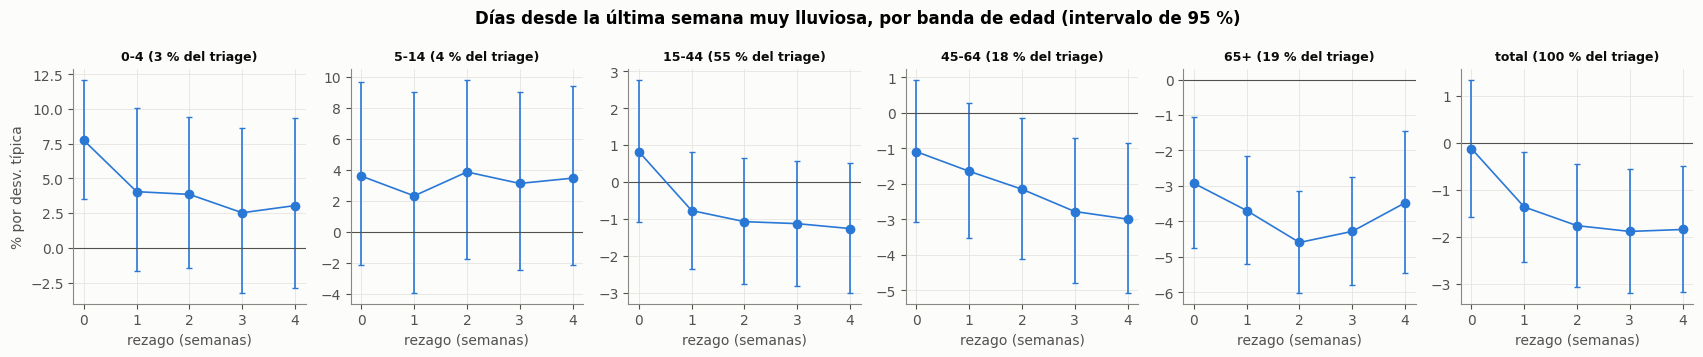

In [14]:
v = "dias_desde_semana_muy_lluviosa"
fig, axes = plt.subplots(1, 6, figsize=(17, 3.6), sharex=True)
for ax, (c, T) in zip(axes, TB.items()):
    t = T[T.variable == v].sort_values("rezago")
    ax.errorbar(t.rezago, t["efecto %"], yerr=[t["efecto %"] - t.ic_bajo, t.ic_alto - t["efecto %"]], color=AZUL, marker="o", capsize=2, lw=1.2)
    ax.axhline(0, color=TINTA2, lw=.8); ax.set_title(f"{c} ({peso[c]:.0f} % del triage)", fontsize=9); ax.set_xlabel("rezago (semanas)")
axes[0].set_ylabel("% por desv. típica")
fig.suptitle("Días desde la última semana muy lluviosa, por banda de edad (intervalo de 95 %)", fontweight="bold"); plt.tight_layout(); plt.show()

**Lectura.** La figura abre la variable «días desde la última semana muy lluviosa» por rezago. En los mayores de 65 años el efecto es negativo en los cinco rezagos y su intervalo de 95 % no incluye el cero en ninguno; crece de −2,9 % en la misma semana a −4,6 % a 2 semanas y vuelve a −3,5 % a 4 semanas, es decir, **actúa con un rezago de varios días a semanas**, como debe ser si pasa por una enfermedad que se incuba y se descompensa. En 45-64 el mismo perfil es más débil y se aleja del cero solo a 2-4 semanas. En 0-4 años el efecto es positivo, con un intervalo ancho que solo excluye el cero en el rezago 0. En el total, el efecto de la lluvia reciente se parece al de los mayores pero con menos de la mitad de su tamaño (−1,9 % a 3 semanas), porque en él se promedian bandas de signos distintos.

---
# 8. Dilución del efecto desde la IRA de la ciudad hasta el triage total

El efecto del clima en la IRA de Manizales es de 6-7 % por desviación típica, y en el triage total de 1,5-2,4 %.
Hay dos razones de que se achique, y se pueden poner en cifras. La primera es de composición: el total suma bandas
de edad con pesos muy distintos, y el efecto del total es el promedio de los efectos por banda ponderado por su
peso. La segunda es de ruido: un desenlace pequeño tiene un error estándar mayor, y solo deja ver efectos grandes.

In [15]:
def spec_mejor(c):
    t = TB[c][TB[c].q < .10]; r = (t if len(t) else TB[c]).sort_values("p").iloc[0]; return r.variable, int(r.rezago)
bandas = ["0-4", "5-14", "15-44", "45-64", "65+"]
out = []
for ancla in ["65+", "total"]:
    v, L = spec_mejor(ancla)
    fila = {b: TB[b].query("variable == @v and rezago == @L")["efecto %"].iloc[0] for b in bandas + ["total"]}
    out.append({"se elige según": ancla, "variable": v, "rezago": L, **{f"efecto {b} %": round(fila[b], 2) for b in bandas},
                "suma ponderada %": round(sum(peso[b] / 100 * fila[b] for b in bandas), 2), "efecto medido en el total %": round(fila["total"], 2)})
print("Pesos de las bandas en el triage (%):", peso[bandas].to_dict(), "| suma:", round(peso[bandas].sum(), 1))
pd.DataFrame(out).set_index("se elige según").T

Pesos de las bandas en el triage (%): {'0-4': 3.0, '5-14': 4.4, '15-44': 55.3, '45-64': 18.4, '65+': 18.8} | suma: 99.9


se elige según,65+,total
variable,dias_desde_semana_muy_lluviosa,dias_en_racha_seca
rezago,2,3
efecto 0-4 %,3.85,-2.3
efecto 5-14 %,3.87,-2.42
efecto 15-44 %,-1.08,2.79
efecto 45-64 %,-2.15,2.79
efecto 65+ %,-4.59,1.12
suma ponderada %,-1.57,2.09
efecto medido en el total %,-1.76,2.09


**Lectura.** La tabla toma dos combinaciones de variable y rezago, una elegida según los mayores de 65 y otra según el total, y compara el efecto de cada banda con el del total. Como el total es la suma de las bandas, su efecto es el promedio de los efectos por banda ponderado por el peso de cada una: la suma ponderada coincide con la medida directa (−1,57 frente a −1,76 en el primer caso, +2,09 frente a +2,09 en el segundo).

- **Con la lluvia reciente (rezago 2)**, el efecto de −4,6 % en los mayores aporta solo −0,86 puntos al total, porque los mayores son el 18,8 % del triage. Los adultos de 15-44, con un efecto de apenas −1,1 %, aportan −0,60 por pesar el 55,3 %. Los niños aportan en sentido contrario (+0,12 y +0,17). Un efecto de 4,6 % en una banda se convierte en una fracción de 1 a 2 % en el total.
- **Con la racha seca (rezago 3)**, el efecto del total (+2,1 %) viene casi todo de los adultos: 15-44 aporta +1,54 de los +2,09 puntos.
- **Las bandas de edad no se mueven en la misma dirección.** Los niños y los adultos tienen signos opuestos, por lo que el total no solo diluye el efecto de la banda sensible sino que lo cancela en parte.

Las dos combinaciones se escogieron mirando los resultados, de modo que la tabla ilustra la aritmética de la composición y no es una prueba.

266 pares variable-rezago. Correlación del efecto en la IRA con el efecto en el triage total: -0.35
Mismo signo en 39 % de los pares; entre los 53 que sobreviven en la IRA, en 19 %.
{'ninguno': 183, 'solo la IRA': 47, 'solo el triage': 30, 'ambos': 6}


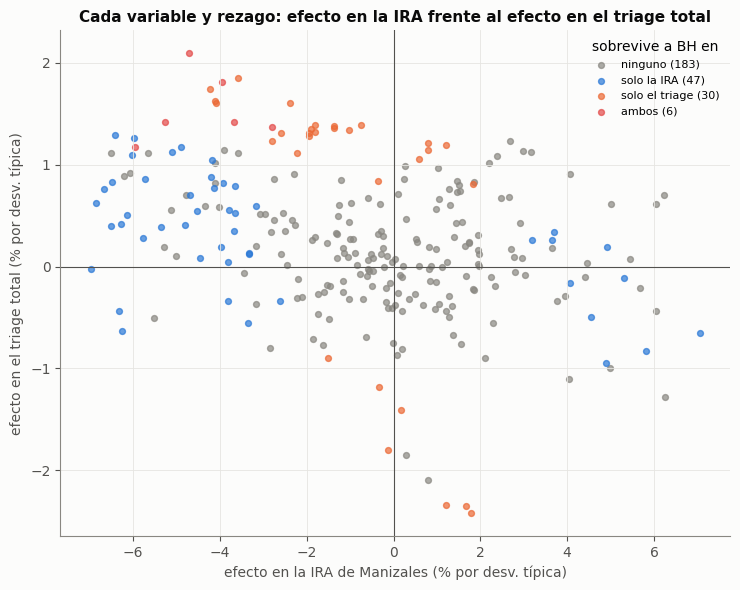

Misma ventana (2022-03 a 2024-12, 148 semanas): la IRA tiene 32 pruebas que sobreviven; correlación de efectos IRA-triage -0.27; mismo signo en 40 % de los pares.


,error estándar mediano (% por desv. típica),"efecto mínimo detectable (% , 2,8 × error)",semanas
IRA de Manizales,1.50,4.2,585.0
ingresos respiratorios del hospital,3.45,9.7,209.0
triage total (sin calendario ni red),0.45,1.2,147.0


In [16]:
M2 = RES["IRA de Manizales"].merge(RES["triage total (sin calendario ni red)"], on=["variable", "rezago"], suffixes=("_ira", "_tot"))
M2["sobrevive en"] = np.select([(M2.q_ira < .10) & (M2.q_tot < .10), M2.q_ira < .10, M2.q_tot < .10], ["ambos", "solo la IRA", "solo el triage"], "ninguno")
mismo = np.sign(M2["efecto %_ira"]) == np.sign(M2["efecto %_tot"])
print(f"{len(M2)} pares variable-rezago. Correlación del efecto en la IRA con el efecto en el triage total: {M2['efecto %_ira'].corr(M2['efecto %_tot']):.2f}")
print(f"Mismo signo en {100 * mismo.mean():.0f} % de los pares; entre los {int((M2.q_ira < .10).sum())} que sobreviven en la IRA, en {100 * mismo[M2.q_ira < .10].mean():.0f} %.")
print(M2["sobrevive en"].value_counts().to_dict())
fig, ax = plt.subplots(figsize=(7.5, 6))
for g, col in [("ninguno", MUDO), ("solo la IRA", AZUL), ("solo el triage", NARANJA), ("ambos", ROJO)]:
    t = M2[M2["sobrevive en"] == g]; ax.scatter(t["efecto %_ira"], t["efecto %_tot"], s=18, color=col, alpha=.7, label=f"{g} ({len(t)})")
ax.axhline(0, color=TINTA2, lw=.8); ax.axvline(0, color=TINTA2, lw=.8)
ax.set_xlabel("efecto en la IRA de Manizales (% por desv. típica)"); ax.set_ylabel("efecto en el triage total (% por desv. típica)")
ax.set_title("Cada variable y rezago: efecto en la IRA frente al efecto en el triage total"); ax.legend(title="sobrevive a BH en", fontsize=8)
plt.tight_layout(); plt.show()
corto = barrido(DES["IRA de Manizales"].loc["2022-03-06":], F)
M3 = corto.merge(RES["triage total (sin calendario ni red)"], on=["variable", "rezago"], suffixes=("_ira", "_tot"))
print(f"Misma ventana (2022-03 a 2024-12, {int(corto.n.median())} semanas): la IRA tiene {int((corto.q < .10).sum())} pruebas que sobreviven; "
      f"correlación de efectos IRA-triage {M3['efecto %_ira'].corr(M3['efecto %_tot']):.2f}; mismo signo en {100 * (np.sign(M3['efecto %_ira']) == np.sign(M3['efecto %_tot'])).mean():.0f} % de los pares.")
ee = pd.DataFrame({k: {"error estándar mediano (% por desv. típica)": round(T["ee %"].median(), 2),
                       "efecto mínimo detectable (% , 2,8 × error)": round(2.8 * T["ee %"].median(), 1),
                       "semanas": int(T.n.median())} for k, T in RES.items()}).T
ee

**Lectura.** Había una hipótesis natural: que el efecto de 1,5 a 2,4 % en el triage total fuera el de la IRA de la ciudad (6-7 %) diluido por el peso de lo respiratorio. Los datos no la sostienen.

- **Los efectos de la IRA y del triage total no van en el mismo sentido.** Entre los 266 pares de variable y rezago, la correlación entre los dos efectos es de −0,35 y el signo coincide en el 39 % de los pares; entre los 53 que sobreviven en la IRA, coincide en el 19 %. Solo 6 pares sobreviven en los dos desenlaces. Con la IRA restringida a la misma ventana del triage (2022-03 a 2024-12) el resultado se mantiene: correlación de −0,27 y 40 % de coincidencia de signo. Una dilución pura mostraría correlación positiva y mismo signo.
- **El ruido sí limita lo que se puede ver.** El error estándar mediano es de 1,50 puntos en la IRA, 3,45 en los ingresos respiratorios y 0,45 en el triage total, de modo que el efecto mínimo detectable (2,8 errores estándar, sin corregir por pruebas múltiples) es de 4,2, 9,7 y 1,2 %. Los ingresos respiratorios (unos 39 por semana, que equivalen a cerca del 2,8 % de las 1.430 consultas de triage semanales de 2022-2024) no pueden mostrar un efecto de 6-7 %. Esa comparación mezcla ventanas (2021-2024 y 2022-2024) y mide ingresos, no triage, de modo que es un orden de magnitud.

La lectura que sostienen los datos es otra: el triage total responde a variables que no son las que mueven la IRA de la ciudad (racha seca, calor del mes, lluvia reciente en los mayores), con efectos distintos por banda de edad. La IRA de la ciudad refleja sobre todo consulta ambulatoria de población general, mientras que el triage de este hospital es urgencia de una red concreta, con otros motivos de consulta. Con estos datos no se puede separar si la diferencia viene de la población, del tipo de servicio o del periodo.

---
# 9. Conclusiones y límites

**Conclusiones**

1. **El clima completo existe como dato** (`calendarios/clima_completo.csv.gz`, 2010-2026): sol, nubes, punto de rocío, sequedad del aire, rachas, extremos y transición. La lluvia del ERA5 se descartó por estar rota (diez veces lo real); la de NASA solo se usa en ventanas de 7 días o más.
2. **El clima mueve con claridad la IRA de la ciudad.** Un mes lluvioso, nublado, húmedo y con poco sol se asocia con 6-7 % más IRA de 1 a 5 semanas después: 53 hallazgos sobreviven a BH frente a unos 13 que daría la cuenta ingenua del 5 % (el azar calibrado del cuaderno 12 da 0,75), aunque son una sola configuración vista desde variables muy correlacionadas.
3. **Al triage total llega algo distinto, no una versión diluida.** Sobreviven 36 hallazgos con efectos de 1,5 a 2,4 %, pero con otras variables y con signo contrario al de la IRA en la mayoría de los pares (correlación de efectos de −0,35). La calibración del azar del cuaderno 12 muestra que esos 36 pasan a 18 si el mes de la semana se toma de su mitad y no de su primer día (el azar da 12,7), de modo que en el total no se puede separar la señal del clima del azar ni de la fecha.
4. **En las hospitalizaciones respiratorias no sobrevive ninguno**, y el diseño no podía ver un efecto menor de unos 10 %.
5. **Por edad, los mayores de 65 años respondieron a la lluvia reciente** (−4,6 % por desviación típica a 2 semanas, intervalo que excluye el cero en los cinco rezagos) y los adultos a las rachas secas (+2,8 %). Ese efecto es del periodo de descubrimiento y no se confirmó en 2025-2026 (cuaderno 21), por lo que no se presenta como firma estable. En ese periodo aporta solo −0,86 puntos al total porque los mayores son el 18,8 % del triage, y los niños se mueven en sentido contrario.
6. **Los episodios de seco a lluvioso no muestran un efecto consistente.** En la IRA (29 episodios) la mediana es de +2,5 % y el promedio de −6,1 %, sin distinguirse del azar; en el triage total, 10 episodios, demasiado pocos para ver un efecto de 1,5 a 2,4 %.
7. **Al modelo deben entrar índices y no variables sueltas:** 4 de estado del clima y 3 de cambio, más dos o tres rachas.

**Límites**

- Todo es exploración en 2010-2024; que sirva para predecir se decide con 2025 y se prueba en 2026 (cuaderno 22).
- Es clima observado. En operación se necesitará el pronóstico (Open-Meteo Previous Runs, desde 2024).
- Las 38 variables son muy redundantes: los hallazgos no son evidencias independientes y la corrección de BH se aplica por desenlace, no entre desenlaces ni entre bandas.
- La transición de seco a lluvioso tiene pocos episodios (29 con IRA, 10 con triage) y los resultados de la sección 6 no permiten decir ni que el giro eleva la demanda ni que no la eleva.
- La IRA de la ciudad y el triage del hospital son poblaciones distintas, y las ventanas de los desenlaces no coinciden (2012-2024, 2021-2024 y 2022-2024).
- Las combinaciones de la tabla de composición se escogieron mirando los resultados y ilustran la aritmética; no son una prueba.